# Khmer Handwriting Recognition 

## Train the Hybrid Quantum-Classical Model

In [7]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pennylane as qml
from pennylane import numpy as pnp

sys.path.insert(0, str(Path("../../src").resolve()))
import quantum_model as qm  # noqa: E402
from config import QUANTUM_MODELS_DIR  # noqa: E402

READY_DIR = Path("../../data/3_ready/cnn_alphabet")
MODELS_DIR = QUANTUM_MODELS_DIR
CHARTS_DIR = Path("../../results/charts/training")
TABLES_DIR = Path("../../results/tables/training")
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

QUBIT_SIZES = [4, 6, 8]
# Sweep breadth; qm.N_LAYERS (10) is also the deployed/canonical choice -- whichever sweep
# run matches it also gets saved as best.npz, which 06_export.ipynb and the backend read.
LAYER_VALUES = [2, 3, 4, qm.N_LAYERS]
MAX_EPOCHS = 60
PATIENCE = 15
BATCH_SIZE = 32
LEARNING_RATE = 0.05
SEED = 0
print(f"qubit_sizes={QUBIT_SIZES}, layer_values={LAYER_VALUES}, canonical_layers={qm.N_LAYERS}")

qubit_sizes=[4, 6, 8], layer_values=[2, 3, 4, 10], canonical_layers=10


In [8]:
def load_qubit_data(n_qubits):
    data = np.load(READY_DIR / f"input_alphabet_{n_qubits}_qubits.npz")
    return (
        pnp.array(data["train_features"]), data["train_labels"],
        pnp.array(data["val_features"]), data["val_labels"],
        pnp.array(data["test_features"]), data["test_labels"],
    )

## Train one hybrid model per (qubit count, layer count)

In [9]:
def train_one_model(n_qubits, n_layers):
    X_train, y_train, X_val, y_val, X_test, y_test = load_qubit_data(n_qubits)
    n_classes = int(max(y_train.max(), y_val.max(), y_test.max())) + 1
    qnode = qm.make_qnode(n_qubits, n_layers=n_layers, noise_prob=0.0)

    circuit_weights = qm.init_weights(n_qubits, n_layers=n_layers, seed=SEED)
    head_weight, head_bias, log_scale = qm.init_head_params(n_qubits, n_classes, seed=SEED)
    params = (circuit_weights, head_weight, head_bias, log_scale)

    def class_probs(X, cw, hw, hb, ls):
        feats = pnp.stack(qnode(X, cw), axis=-1)
        return qm.apply_head(feats, hw, hb, ls)

    opt = qml.AdamOptimizer(stepsize=LEARNING_RATE)
    rng = np.random.default_rng(SEED)
    n_train = len(X_train)

    best_val_acc = -1.0
    best_params = params
    best_epoch = 0
    epochs_without_improve = 0
    history = []
    tag = f"{n_qubits}q-{n_layers}L"

    for epoch in range(1, MAX_EPOCHS + 1):
        perm = rng.permutation(n_train)
        X_shuffled = X_train[perm]
        y_shuffled = y_train[perm]

        epoch_losses = []
        for start in range(0, n_train, BATCH_SIZE):
            X_batch = X_shuffled[start:start + BATCH_SIZE]
            y_batch = y_shuffled[start:start + BATCH_SIZE]

            def cost(*p, X_batch=X_batch, y_batch=y_batch):
                return qm.cross_entropy(class_probs(X_batch, *p), y_batch)

            new_params, loss_val = opt.step_and_cost(cost, *params)
            params = tuple(new_params)
            epoch_losses.append(float(loss_val))

        train_loss = float(np.mean(epoch_losses))
        val_acc = qm.accuracy(class_probs(X_val, *params), y_val)
        history.append({"qubits": n_qubits, "layers": n_layers, "epoch": epoch, "train_loss": train_loss, "val_accuracy": val_acc})
        print(f"[{tag}, {n_classes}cls] epoch {epoch:2d}  train_loss={train_loss:.4f}  val_acc={val_acc:.3f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_params = tuple(pnp.array(p) for p in params)
            best_epoch = epoch
            epochs_without_improve = 0
        else:
            epochs_without_improve += 1
            if epochs_without_improve >= PATIENCE:
                print(f"[{tag}] early stopping at epoch {epoch} (best epoch {best_epoch}, val_acc={best_val_acc:.3f})")
                break

    test_acc = qm.accuracy(class_probs(X_test, *best_params), y_test)

    save_kwargs = dict(
        weights=np.array(best_params[0]),
        best_epoch=best_epoch,
        best_val_accuracy=best_val_acc,
        test_accuracy=test_acc,
        n_classes=n_classes,
        reupload=qm.default_reupload(n_qubits),
        head_weight=np.array(best_params[1]),
        head_bias=np.array(best_params[2]),
        log_scale=float(best_params[3]),
        output_grouping="head",
    )

    model_dir = MODELS_DIR / f"{n_qubits}q"
    model_dir.mkdir(parents=True, exist_ok=True)
    # Every (qubits, layers) combination gets its own checkpoint...
    np.savez(model_dir / f"{n_layers}layers.npz", **save_kwargs)
    # ...and whichever run matches the canonical/deployed layer count also gets saved as
    # best.npz, which 06_export.ipynb and the backend actually read.
    if n_layers == qm.N_LAYERS:
        np.savez(model_dir / "best.npz", **save_kwargs)

    print(f"[{tag}] DONE -> best_epoch={best_epoch} val_acc={best_val_acc:.3f} test_acc={test_acc:.3f}\n")
    return history, best_epoch, best_val_acc, test_acc, n_classes

In [10]:
all_history = []
summary_rows = []

for n_qubits in QUBIT_SIZES:
    for n_layers in LAYER_VALUES:
        history, best_epoch, best_val_acc, test_acc, n_classes = train_one_model(n_qubits, n_layers)
        all_history.extend(history)
        summary_rows.append({
            "qubits": n_qubits,
            "layers": n_layers,
            "n_classes": n_classes,
            "best_epoch": best_epoch,
            "best_val_accuracy": round(best_val_acc, 4),
            "test_accuracy": round(test_acc, 4),
        })

summary_rows

[4q-2L, 16cls] epoch  1  train_loss=1.1334  val_acc=0.833
[4q-2L, 16cls] epoch  2  train_loss=0.1684  val_acc=0.891
[4q-2L, 16cls] epoch  3  train_loss=0.0956  val_acc=0.922
[4q-2L, 16cls] epoch  4  train_loss=0.0751  val_acc=0.922
[4q-2L, 16cls] epoch  5  train_loss=0.0698  val_acc=0.917
[4q-2L, 16cls] epoch  6  train_loss=0.1355  val_acc=0.911
[4q-2L, 16cls] epoch  7  train_loss=0.1022  val_acc=0.927
[4q-2L, 16cls] epoch  8  train_loss=0.0505  val_acc=0.943
[4q-2L, 16cls] epoch  9  train_loss=0.0461  val_acc=0.917
[4q-2L, 16cls] epoch 10  train_loss=0.0856  val_acc=0.948
[4q-2L, 16cls] epoch 11  train_loss=0.0586  val_acc=0.927
[4q-2L, 16cls] epoch 12  train_loss=0.0454  val_acc=0.922
[4q-2L, 16cls] epoch 13  train_loss=0.0524  val_acc=0.932
[4q-2L, 16cls] epoch 14  train_loss=0.0236  val_acc=0.938
[4q-2L, 16cls] epoch 15  train_loss=0.0961  val_acc=0.896
[4q-2L, 16cls] epoch 16  train_loss=0.0542  val_acc=0.964
[4q-2L, 16cls] epoch 17  train_loss=0.0327  val_acc=0.911
[4q-2L, 16cls]

[{'qubits': 4,
  'layers': 2,
  'n_classes': 16,
  'best_epoch': 16,
  'best_val_accuracy': 0.9635,
  'test_accuracy': 0.9219},
 {'qubits': 4,
  'layers': 3,
  'n_classes': 16,
  'best_epoch': 15,
  'best_val_accuracy': 0.9479,
  'test_accuracy': 0.9583},
 {'qubits': 4,
  'layers': 4,
  'n_classes': 16,
  'best_epoch': 28,
  'best_val_accuracy': 0.9531,
  'test_accuracy': 0.9531},
 {'qubits': 4,
  'layers': 10,
  'n_classes': 16,
  'best_epoch': 26,
  'best_val_accuracy': 0.9323,
  'test_accuracy': 0.8854},
 {'qubits': 6,
  'layers': 2,
  'n_classes': 33,
  'best_epoch': 18,
  'best_val_accuracy': 0.904,
  'test_accuracy': 0.904},
 {'qubits': 6,
  'layers': 3,
  'n_classes': 33,
  'best_epoch': 28,
  'best_val_accuracy': 0.9066,
  'test_accuracy': 0.9091},
 {'qubits': 6,
  'layers': 4,
  'n_classes': 33,
  'best_epoch': 5,
  'best_val_accuracy': 0.8763,
  'test_accuracy': 0.8864},
 {'qubits': 6,
  'layers': 10,
  'n_classes': 33,
  'best_epoch': 36,
  'best_val_accuracy': 0.9091,
  'te

## Save training curves (table + chart)

In [11]:
with open(TABLES_DIR / "training_history_alphabet.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["qubits", "layers", "epoch", "train_loss", "val_accuracy"])
    writer.writeheader()
    writer.writerows(all_history)

with open(TABLES_DIR / "training_summary_alphabet.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["qubits", "layers", "n_classes", "best_epoch", "best_val_accuracy", "test_accuracy"])
    writer.writeheader()
    writer.writerows(summary_rows)

canonical_history = [h for h in all_history if h["layers"] == qm.N_LAYERS]

print("Wrote:", MODELS_DIR)
print("Wrote:", TABLES_DIR / "training_summary_alphabet.csv")

Wrote: D:\Cadt\Year4\Quantum Computing\Khmer_Handwriting_Recognition\models\quantum
Wrote: ..\..\results\tables\training\training_summary_alphabet.csv


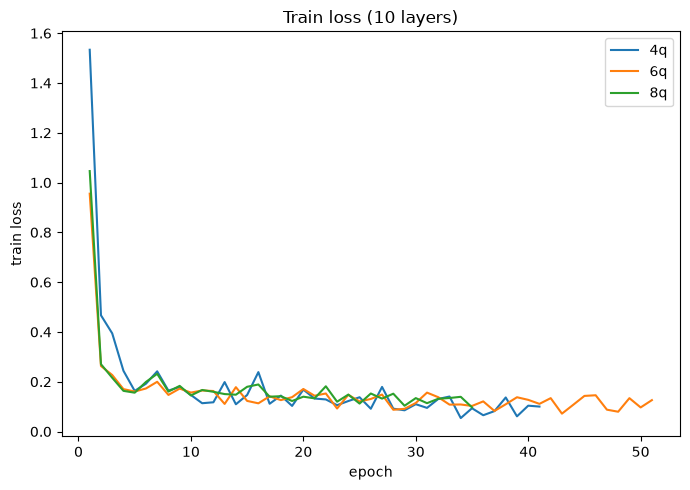

Wrote: ..\..\results\charts\training\training_loss_alphabet.png


In [12]:
plt.figure(figsize=(7, 5))
for n_qubits in QUBIT_SIZES:
    rows = [h for h in canonical_history if h["qubits"] == n_qubits]
    epochs = [r["epoch"] for r in rows]
    plt.plot(epochs, [r["train_loss"] for r in rows], label=f"{n_qubits}q")
plt.title(f"Train loss ({qm.N_LAYERS} layers)")
plt.xlabel("epoch")
plt.ylabel("train loss")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "training_loss_alphabet.png", dpi=150)
plt.show()

print("Wrote:", CHARTS_DIR / "training_loss_alphabet.png")

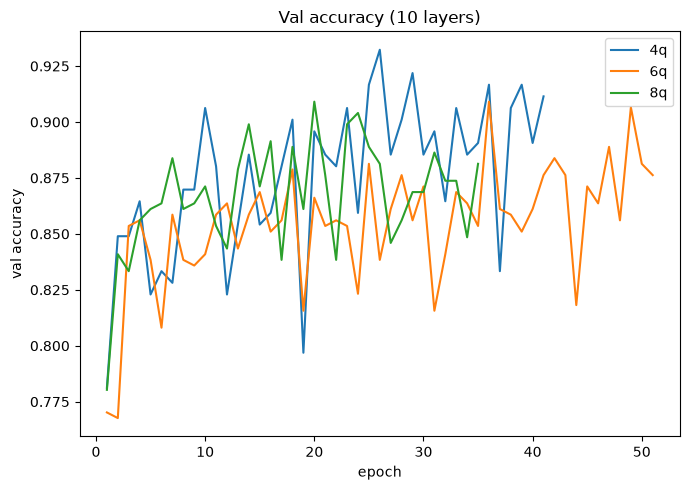

Wrote: ..\..\results\charts\training\training_val_accuracy_alphabet.png


In [13]:
plt.figure(figsize=(7, 5))
for n_qubits in QUBIT_SIZES:
    rows = [h for h in canonical_history if h["qubits"] == n_qubits]
    epochs = [r["epoch"] for r in rows]
    plt.plot(epochs, [r["val_accuracy"] for r in rows], label=f"{n_qubits}q")
plt.title(f"Val accuracy ({qm.N_LAYERS} layers)")
plt.xlabel("epoch")
plt.ylabel("val accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(CHARTS_DIR / "training_val_accuracy_alphabet.png", dpi=150)
plt.show()

print("Wrote:", CHARTS_DIR / "training_val_accuracy_alphabet.png")